# Review 2 — Time Series

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'config.yaml').exists())
TS=ROOT/'reports/review2/ts'
TEXT=ROOT/'reports/review2/text'
def table(path):
    frame=pd.read_csv(ROOT/path)
    display(frame)
    return frame
def figure(path): display(Image(filename=str(ROOT/path)))


## Unit 3 — Method 1: Time Series
M3 Akshay: STL, stationarity, PELT and ITS. M5 Adhikkesh: forecast design, model selection, backtests and tag classes. Results are observational; event alignment does not establish causation.

In [2]:
series=pd.read_csv(TS/'series_long.csv')
assert len(series)==5600 and series.tag.nunique()==14
assert series.groupby('tag').size().eq(400).all()
display(series.groupby('tag').size().rename('complete weeks'))
display(json.loads((TS/'series_manifest.json').read_text()))

tag
ALL           400
android       400
docker        400
excel         400
fastapi       400
java          400
javascript    400
openai-api    400
pandas        400
powerbi       400
python        400
r             400
reactjs       400
sql           400
Name: complete weeks, dtype: int64

{'weeks': 400,
 'series': 14,
 'missing_weeks': 0,
 'origin_convention': 'first forecast week; training dates < origin',
 'monthly_rates': 'monthly_rates_masked.csv; never presented as weekly measurements',
 'tag_change': '100 * (forecast at week 26 / last observed weekly count - 1)',
 'interval_point': 'back-transformed median forecast, not arithmetic mean',
 'tag_classes': '< -40 steep decline; [-40,-10] declining; > -10 stabilising'}

### Preparation: complete Tuesday-start weekly counts
The 14 weekly series are API total counts for ALL (site-wide) plus 13 study tags, collected separately from the question sample. ALL is not the sum of overlapping tags. Log1p counts support STL, stationarity and forecasting. The final observed complete week starts 2026-08-25; incomplete final weeks are excluded.

,tag,n_weeks,seasonal_strength,trend_strength,peak_phase,peak_month,trough_phase,trough_month,dip_start_phase,dip_end_phase,dip_name
0,ALL,400,0.574431,0.996913,9,March,0,January,51,1,January / December
1,java,400,0.491630,0.994693,12,March,32,August,25,41,June / July / August / September / October
2,r,400,0.436311,0.989866,12,March,0,January,51,1,January / December
3,python,400,0.363574,0.994997,9,March,0,January,51,1,January / December
4,excel,400,0.337278,0.985928,10,March,0,January,50,0,January / December
5,docker,400,0.302096,0.982918,6,February,33,August,32,33,August
6,fastapi,400,0.265559,0.935857,16,April,35,September,33,38,August / September
7,sql,400,0.246836,0.989156,8,February,0,January,50,3,January / December
8,android,400,0.199495,0.991032,8,February,32,August,29,32,July / August
9,powerbi,400,0.192483,0.944640,48,December,0,January,49,1,January / December


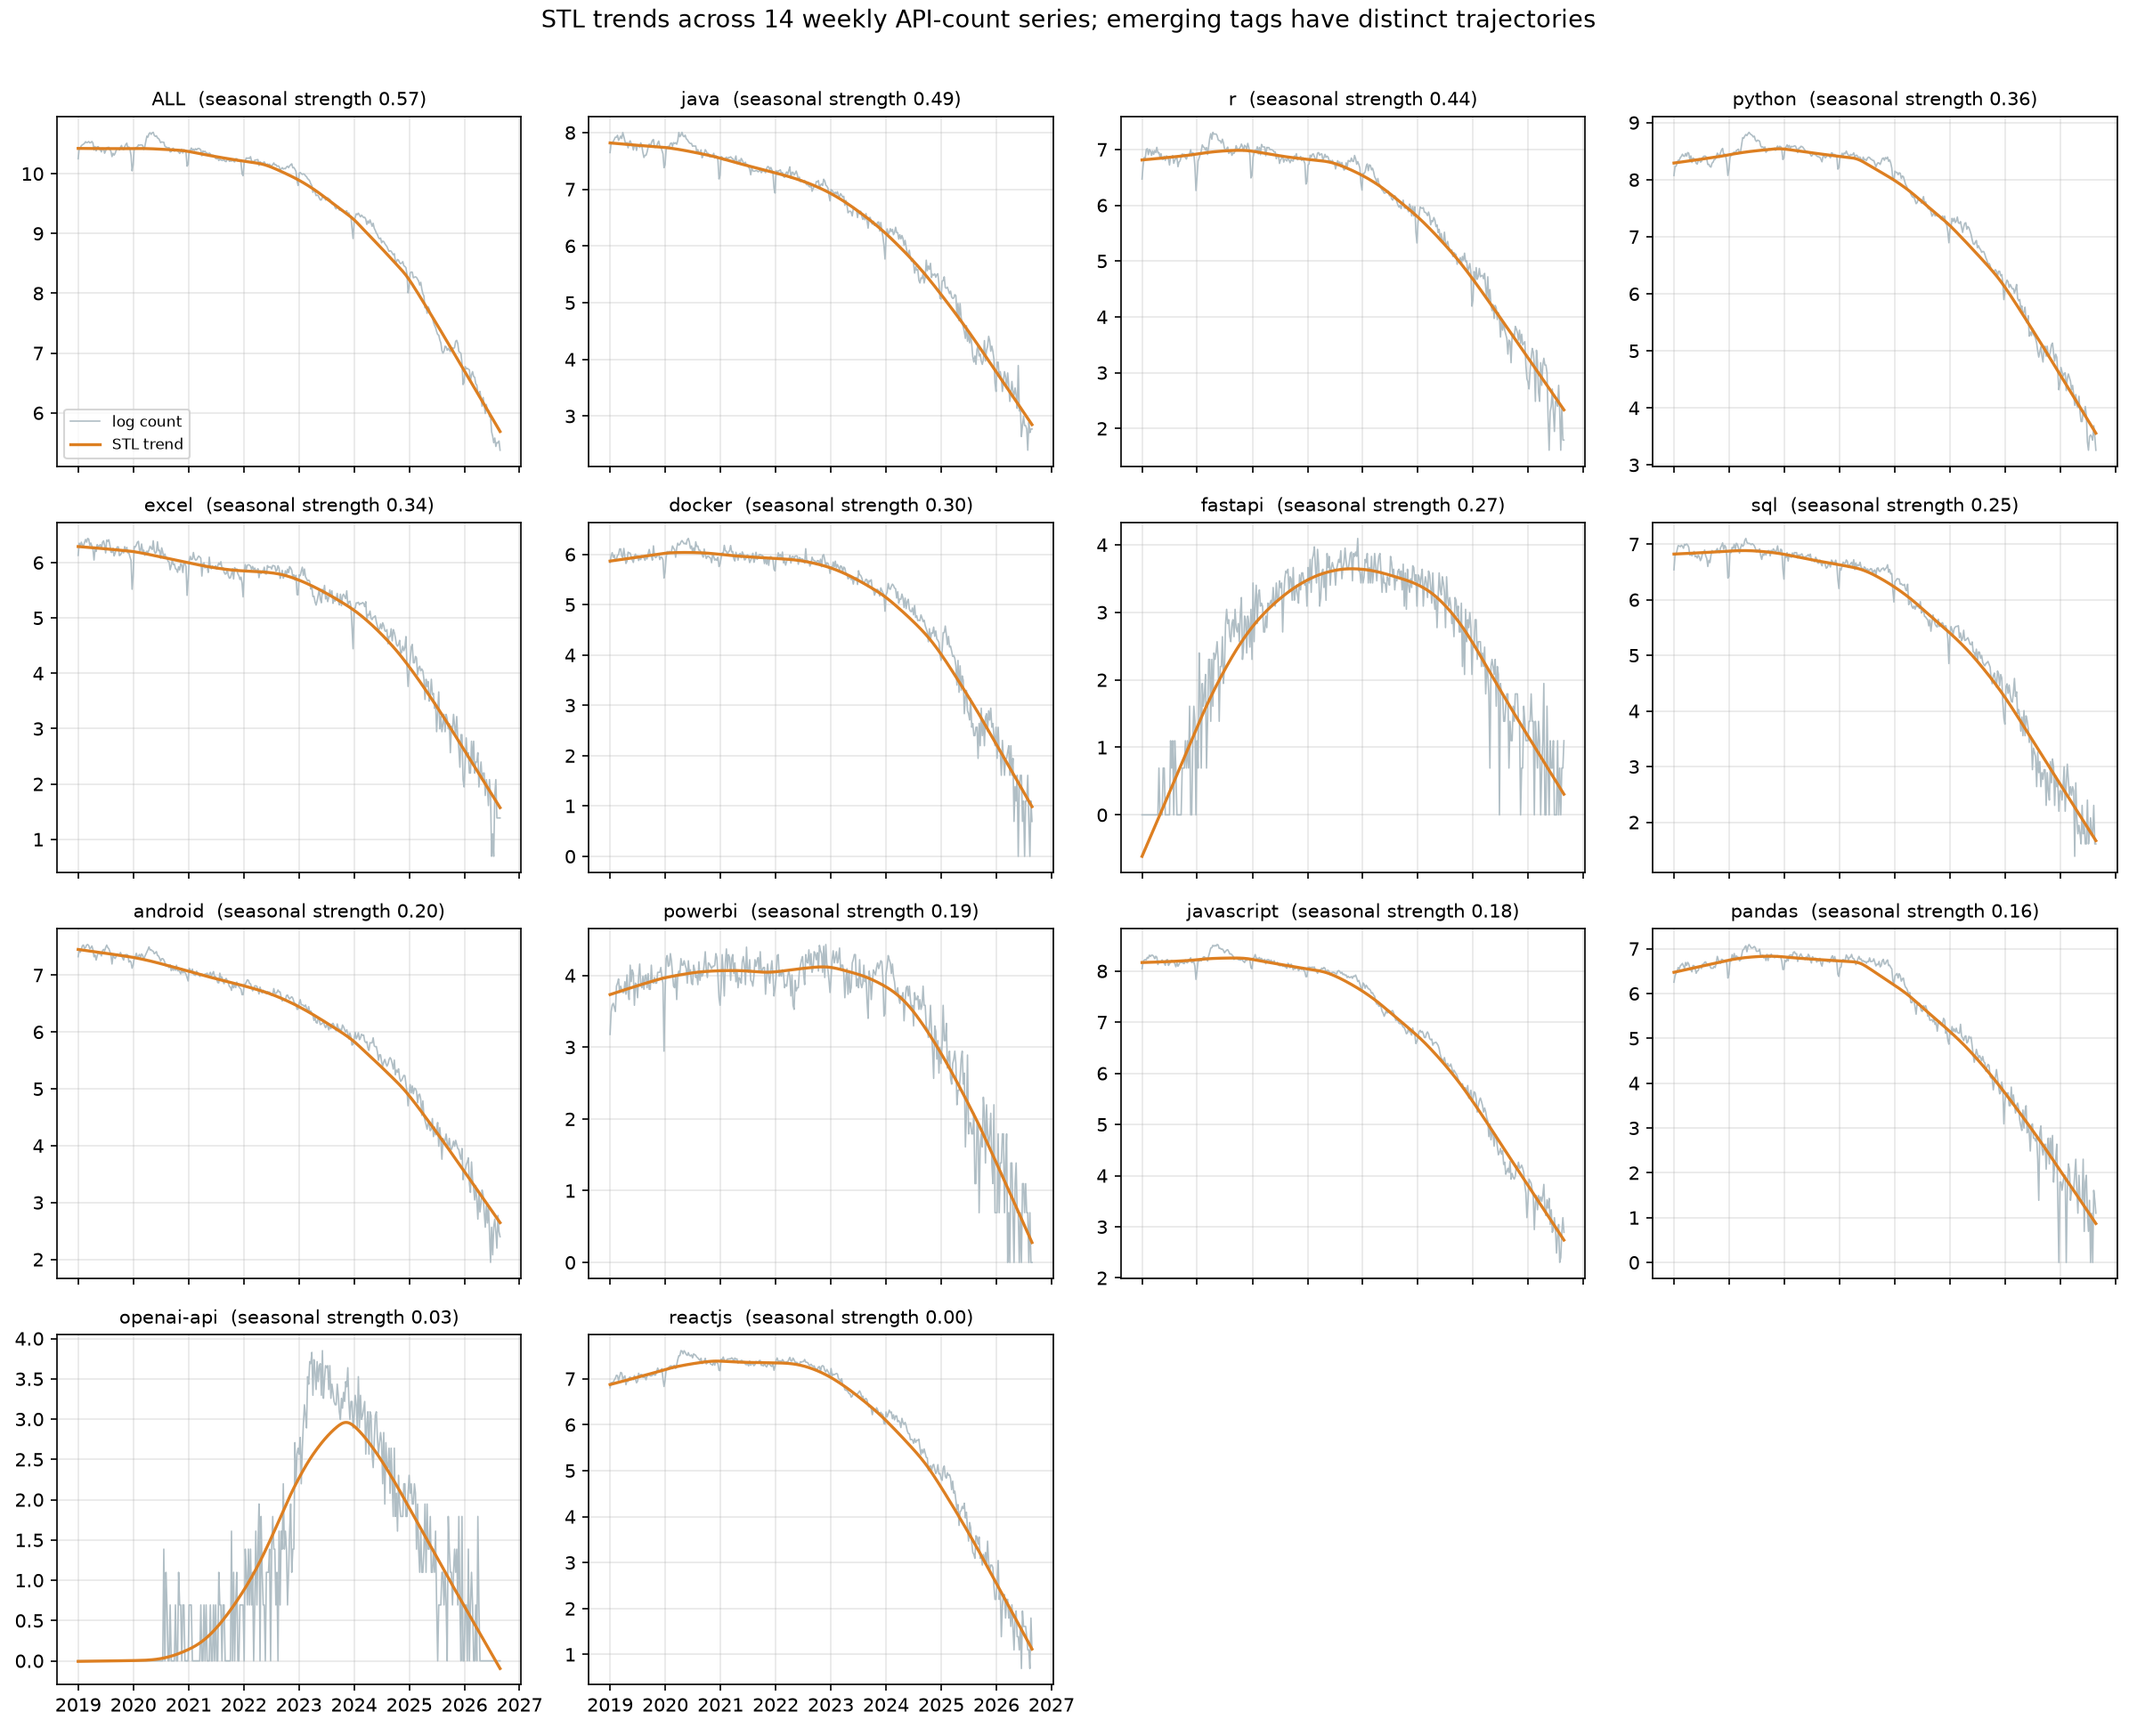

,tag,adf_level_p,kpss_level_p,adf_diff_p,kpss_diff_p,level_verdict,diff_verdict,differencing_decision,rationale
0,ALL,1.000000,0.01,2.334794e-29,0.010000,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
1,android,1.000000,0.01,7.197399e-03,0.010000,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
2,docker,1.000000,0.01,3.150275e-28,0.010000,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
3,excel,1.000000,0.01,1.639740e-29,0.049895,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
4,fastapi,0.617164,0.01,4.602235e-03,0.049281,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
5,java,1.000000,0.01,2.130813e-08,0.010000,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
6,javascript,1.000000,0.01,3.135978e-04,0.010000,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
7,openai-api,0.611627,0.01,3.237836e-03,0.100000,non-stationary,stationary,d=1,ADF cannot reject a unit root and KPSS rejects...
8,pandas,1.000000,0.01,4.671155e-13,0.014519,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...
9,powerbi,1.000000,0.01,9.465778e-20,0.014054,non-stationary,conflicting evidence,d=1,ADF cannot reject a unit root and KPSS rejects...


Level verdicts: {'non-stationary': 14}
First-difference verdicts: {'conflicting evidence': 12, 'stationary': 2}


In [3]:
display(pd.read_csv(TS/'stl_summary.csv'))
figure('reports/review2/ts/stl_small_multiples.png')
s=pd.read_csv(TS/'stationarity_decision.csv')
display(s)
print('Level verdicts:',s.level_verdict.value_counts().to_dict())
print('First-difference verdicts:',s.diff_verdict.value_counts().to_dict())

### PELT changes and the fixed-date ITS sensitivity check
PELT uses a fixed penalty and minimum segment length. Its detected breaks are not hypothesis-test significance decisions. ITS models log counts with a launch-date level step, post-break slope and seasonal Fourier terms, using HAC errors. The transformed slope change is in percent per week. The single 2021 placebo cannot rule out all confounding.

134 PELT breaks; 6 within four weeks of an event.
Actual slope magnitude exceeds placebo in 13/14 series.


,tag,intervention_date,intervention_week_start,intervention_event,placebo_break_date,n_weeks,n_pre_weeks,n_post_weeks,beta0,beta1,...,status,placebo_level_change,placebo_level_ci_lo,placebo_level_ci_hi,placebo_level_p,placebo_slope_change,placebo_slope_ci_lo,placebo_slope_ci_hi,placebo_slope_p,effect_exceeds_placebo
0,ALL,2022-11-30,2022-11-29,ChatGPT Launch,2021-11-30,400,204,196,10.530945,-0.001899,...,significant post-slope decline,0.987543,0.598784,1.470832,1.395175e-09,-0.017268,-0.019098,-0.015434,8.381970e-55,True
1,android,2022-11-30,2022-11-29,ChatGPT Launch,2021-11-30,400,204,196,7.548772,-0.004658,...,significant post-slope decline,0.845209,0.508018,1.257795,5.369522e-09,-0.012755,-0.014505,-0.011002,2.577619e-37,True
2,docker,2022-11-30,2022-11-29,ChatGPT Launch,2021-11-30,400,204,196,6.025193,-0.000568,...,significant post-slope decline,1.591119,0.890325,2.551716,6.437052e-09,-0.020123,-0.022739,-0.017501,2.559014e-40,True
3,excel,2022-11-30,2022-11-29,ChatGPT Launch,2021-11-30,400,204,196,6.320832,-0.002845,...,significant post-slope decline,1.410736,0.855194,2.132636,1.302053e-10,-0.014080,-0.016242,-0.011913,3.441902e-31,True
4,fastapi,2022-11-30,2022-11-29,ChatGPT Launch,2021-11-30,400,204,196,0.217451,0.021115,...,significant post-slope decline,0.463644,0.048755,1.042664,2.520775e-02,-0.040493,-0.043461,-0.037516,2.627434e-88,False
5,java,2022-11-30,2022-11-29,ChatGPT Launch,2021-11-30,400,204,196,7.950169,-0.004116,...,significant post-slope decline,0.762643,0.459383,1.128919,7.761188e-09,-0.014753,-0.016325,-0.013179,1.594945e-54,True
6,javascript,2022-11-30,2022-11-29,ChatGPT Launch,2021-11-30,400,204,196,8.311053,-0.001557,...,significant post-slope decline,1.043021,0.646191,1.535509,2.390290e-10,-0.021928,-0.023665,-0.020187,4.053862e-81,True
7,openai-api,2022-11-30,2022-11-29,ChatGPT Launch,2021-11-30,400,204,196,-0.276452,0.006428,...,significant post-slope decline,7.161002,2.975120,15.754702,1.918854e-08,-0.008628,-0.013242,-0.003993,2.953562e-04,True
8,pandas,2022-11-30,2022-11-29,ChatGPT Launch,2021-11-30,400,204,196,6.690456,0.000447,...,significant post-slope decline,1.249570,0.781387,1.840799,3.234698e-11,-0.026538,-0.028384,-0.024689,5.292972e-95,True
9,powerbi,2022-11-30,2022-11-29,ChatGPT Launch,2021-11-30,400,204,196,3.872463,0.001323,...,significant post-slope decline,1.273344,0.658126,2.116829,4.881294e-07,-0.016822,-0.019453,-0.014184,3.399399e-30,True


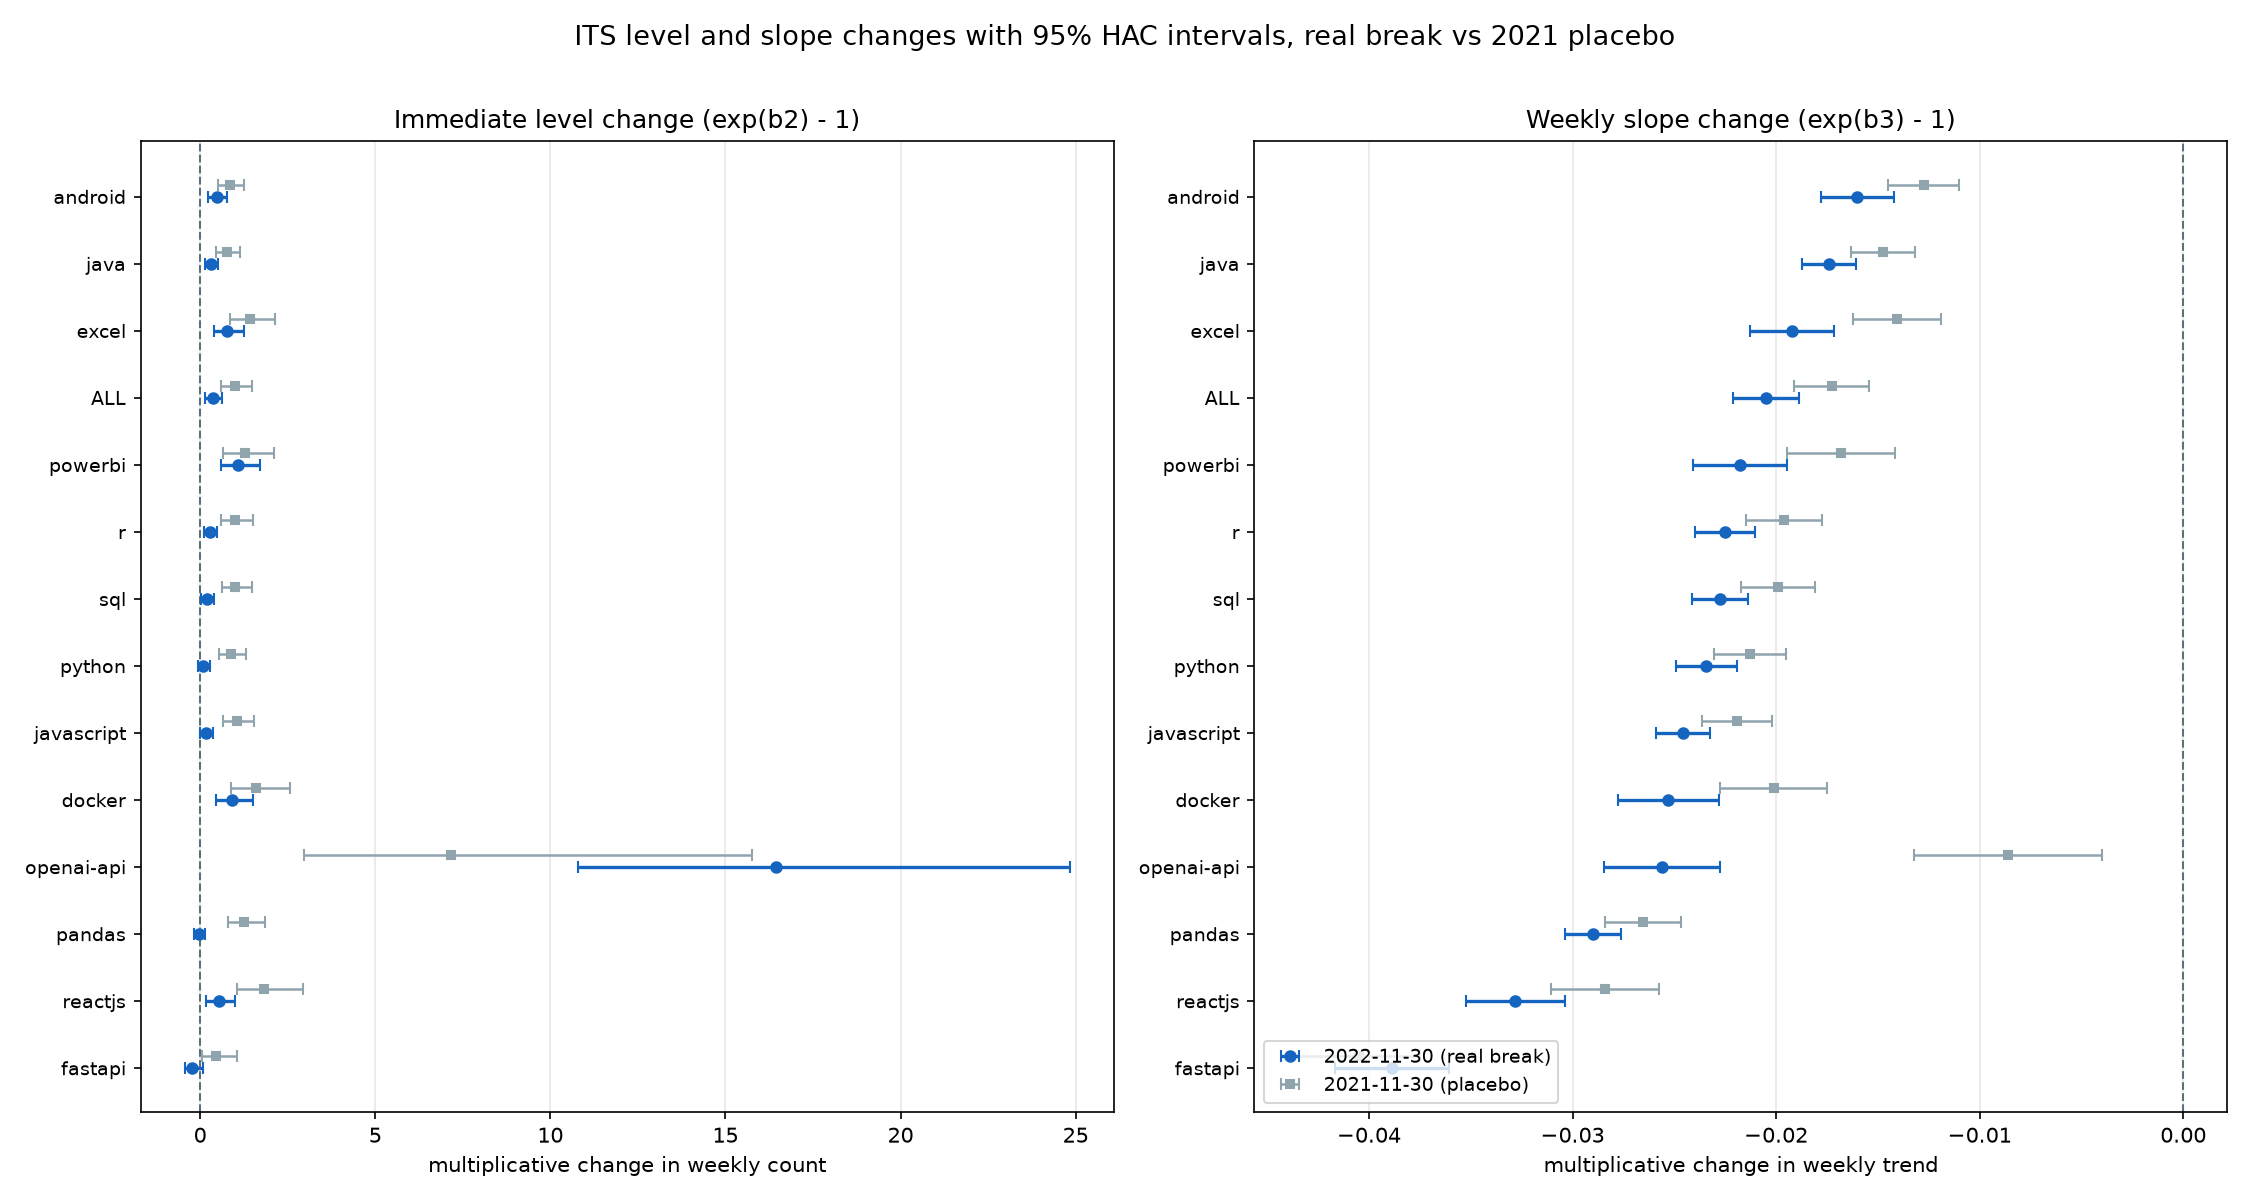

In [4]:
cp=pd.read_csv(TS/'changepoints.csv');its=pd.read_csv(TS/'its_results.csv')
print(f'{len(cp)} PELT breaks; {int(cp.within_4_weeks_of_event.sum())} within four weeks of an event.')
print(f'Actual slope magnitude exceeds placebo in {int(its.effect_exceeds_placebo.sum())}/{len(its)} series.')
display(its)
figure('reports/review2/ts/its_forest.png')

### Forecast preparation and comparison protocol
Three baselines: naive, seasonal naive and drift. Compare ETS and SARIMAX. Orders use training data before July 2024; family selection uses 2024 H2. Separate expanding-window backtests cover 2025–26 at 1, 4, 13 and 26 weeks. Each training cutoff precedes its forecast origin. MASE is an error ratio, not accuracy; lower is better.

,tag,selected_model,p,q,validation_end,selection
0,ALL,sarimax,2,1,2024-12-31,lowest mean validation MASE across four horizo...
1,android,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
2,docker,drift,1,1,2024-12-31,lowest mean validation MASE across four horizo...
3,excel,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
4,fastapi,sarimax,1,2,2024-12-31,lowest mean validation MASE across four horizo...
5,java,sarimax,2,2,2024-12-31,lowest mean validation MASE across four horizo...
6,javascript,sarimax,2,1,2024-12-31,lowest mean validation MASE across four horizo...
7,openai-api,ets,1,1,2024-12-31,lowest mean validation MASE across four horizo...
8,pandas,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
9,powerbi,naive,1,1,2024-12-31,lowest mean validation MASE across four horizo...


Selected model counts: {'sarimax': 9, 'drift': 3, 'ets': 1, 'naive': 1}


,tag,model,horizon,n_origins,mase,smape,coverage80,coverage95,naive_mase,log_rmse,skill_vs_naive
0,ALL,drift,1,7,0.249869,3.949045,0.714286,1.000000,0.255199,0.051371,0.020886
1,ALL,drift,4,6,0.409521,6.194492,1.000000,1.000000,0.548550,0.067193,0.253448
2,ALL,drift,13,4,1.184802,19.269580,1.000000,1.000000,1.640632,0.201431,0.277838
3,ALL,drift,26,1,4.003834,75.739376,0.000000,0.000000,4.936467,0.796892,0.188927
4,ALL,ets,1,7,0.255187,4.014522,0.714286,1.000000,0.255199,0.053575,0.000047
...,...,...,...,...,...,...,...,...,...,...,...
275,sql,sarimax,26,1,1.201133,72.789376,0.000000,0.000000,2.635121,0.751675,0.544183
276,sql,seasonal_naive,1,7,3.279049,77.994470,0.000000,0.285714,0.321910,0.840766,-9.186227
277,sql,seasonal_naive,4,6,3.588923,80.825153,0.000000,0.000000,0.345972,0.857703,-9.373460
278,sql,seasonal_naive,13,4,3.188909,84.722933,0.000000,0.000000,0.890608,0.913025,-2.580597


,model,horizon,n_series,mase,smape,log_rmse,skill_vs_naive,coverage80,coverage95
0,drift,1,14,0.218810,37.092532,0.406094,0.004197,0.491002,0.637369
1,drift,4,14,0.249477,37.991488,0.410250,0.044486,0.672216,0.856525
2,drift,13,14,0.387861,53.760766,0.587033,0.136868,0.704248,0.847044
3,drift,26,14,0.564213,74.611581,0.792137,0.222365,0.667347,0.833036
4,ets,1,14,0.189616,34.947434,0.346303,0.110113,0.493012,0.652675
5,ets,4,14,0.232430,38.255310,0.382306,0.093262,0.496178,0.693000
6,ets,13,14,0.387252,57.058210,0.573650,0.145557,0.413644,0.641518
7,ets,26,14,0.584449,77.056023,0.794480,0.212090,0.338435,0.596726
8,naive,1,14,0.219237,37.059830,0.405908,0.000000,0.487600,0.627474
9,naive,4,14,0.257885,38.474676,0.418104,0.000000,0.655021,0.852766


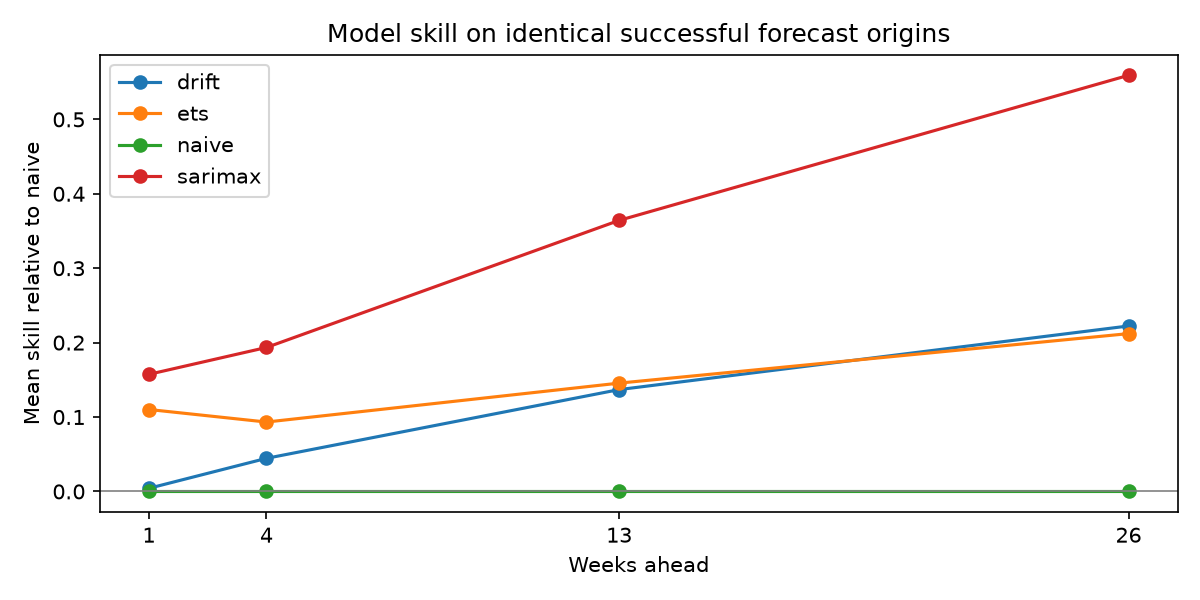

In [5]:
choices=pd.read_csv(TS/'model_choices.csv')
display(choices)
print('Selected model counts:',choices.selected_model.value_counts().to_dict())
display(pd.read_csv(TS/'validation_metrics.csv'))
bp=pd.read_csv(TS/'backtest_predictions.csv')
assert (pd.to_datetime(bp.training_last_week)<pd.to_datetime(bp.origin)).all()
assert set(bp.horizon)=={1,4,13,26}
summary=pd.read_csv(TS/'backtest_summary_matched.csv');display(summary)
figure('reports/review2/ts/backtest_skill.png')

### Evaluation: comparable origins, failures, coverage and diagnostics
Matched-origin comparisons prevent a model appearing better by failing on hard cases. Empirical interval coverage is reported against nominal 80/95%; undercoverage is a limitation. Diebold–Mariano comparisons use the selected model versus naive; inspect actual rows and HAC details. They are exploratory with overlapping horizons.

,tag,origin,model,error
0,docker,2024-12-17,sarimax,SARIMAX did not converge
1,java,2025-02-04,sarimax,SARIMAX did not converge
2,java,2025-10-14,sarimax,SARIMAX did not converge
3,javascript,2026-02-03,sarimax,SARIMAX did not converge
4,pandas,2025-09-16,sarimax,SARIMAX did not converge
5,powerbi,2025-03-04,sarimax,SARIMAX did not converge
6,python,2024-11-19,sarimax,SARIMAX did not converge
7,r,2025-07-22,sarimax,SARIMAX did not converge
8,r,2026-05-26,sarimax,SARIMAX did not converge
9,sql,2024-10-22,sarimax,SARIMAX did not converge


,tag,horizon,model,n,hac_lags,mean_loss_difference,statistic,p_value,loss,note
0,ALL,4,sarimax,21,0,-0.061834,-2.192647,0.040328,absolute count error / training naive scale,negative difference favours selected model; sm...
1,ALL,13,sarimax,19,3,-0.292556,-3.299749,0.003984,absolute count error / training naive scale,negative difference favours selected model; sm...
2,android,4,sarimax,21,0,-0.001032,-0.045222,0.964379,absolute count error / training naive scale,negative difference favours selected model; sm...
3,android,13,sarimax,19,3,-0.152198,-6.600920,0.000003,absolute count error / training naive scale,negative difference favours selected model; sm...
4,docker,4,drift,21,0,-0.012545,-2.055546,0.053118,absolute count error / training naive scale,negative difference favours selected model; sm...
5,docker,13,drift,19,3,-0.060340,-2.839268,0.010880,absolute count error / training naive scale,negative difference favours selected model; sm...
6,excel,4,sarimax,21,0,-0.028544,-1.089201,0.289016,absolute count error / training naive scale,negative difference favours selected model; sm...
7,excel,13,sarimax,19,3,-0.086314,-2.807052,0.011659,absolute count error / training naive scale,negative difference favours selected model; sm...
8,fastapi,4,sarimax,21,0,0.017165,0.276894,0.784703,absolute count error / training naive scale,negative difference favours selected model; sm...
9,fastapi,13,sarimax,19,3,-0.090580,-1.854142,0.080179,absolute count error / training naive scale,negative difference favours selected model; sm...


,tag,model,lag,lb_stat,lb_pvalue
0,ALL,sarimax,10,8.653720,5.652514e-01
1,ALL,sarimax,20,19.637850,4.807789e-01
2,android,sarimax,10,14.226747,1.628980e-01
3,android,sarimax,20,31.221753,5.233019e-02
4,docker,drift,10,285.397574,1.889874e-55
5,docker,drift,20,366.693585,1.602983e-65
6,excel,sarimax,10,12.711226,2.402686e-01
7,excel,sarimax,20,25.172063,1.949275e-01
8,fastapi,sarimax,10,17.110676,7.195059e-02
9,fastapi,sarimax,20,27.142745,1.312955e-01


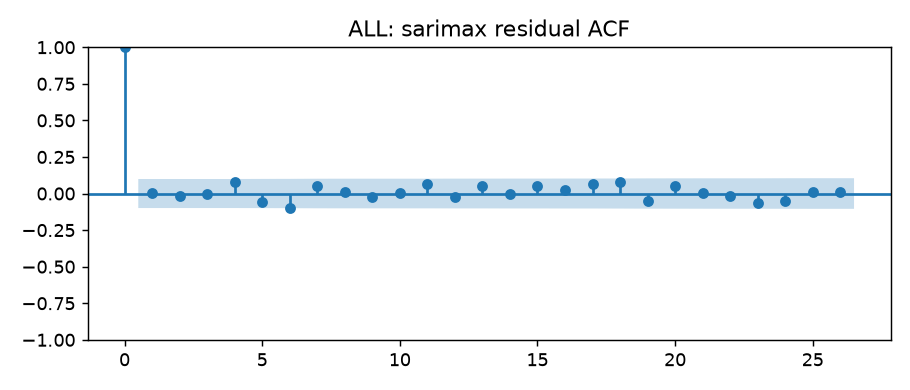

In [6]:
display(pd.read_csv(TS/'fit_failures.csv'))
display(pd.read_csv(TS/'diebold_mariano.csv'))
display(pd.read_csv(TS/'residual_checks.csv'))
figure('reports/review2/ts/acf_ALL.png')

### Forecasts and fixed trajectory classes
Forecasts extend 26 weeks to 2027-02-23. Classes use the written thresholds and the validation-selected model. Zero last-week counts make percentage changes undefined. Forecasts are projections conditional on the saved history, not verified future outcomes.

,tag,selected_model,change_26w_pct,forecast_class,last_week_count,forecast_week26,post2023_log_slope,half_life_weeks,load_index_vs_2025,its_slope_change_pct,its_status,its_slope_ci_lo,its_slope_ci_hi,its_slope_p,post2023_share_pct,share_change_pp,share_trend
0,ALL,sarimax,-37.601441,declining,215.0,134.156902,-0.023054,30.066454,8.275674,-2.050,significant post-slope decline,-2.212,-1.888,1.033572e-81,100.000,0.000,site total (100%)
1,android,sarimax,-39.905595,declining,10.0,6.009441,-0.021246,32.624384,9.912092,-1.601,significant post-slope decline,-1.779,-1.423,3.298613e-51,3.703,-0.198,losing relative share
2,docker,drift,-56.938927,steep decline,1.0,0.430611,-0.026917,25.751500,2.246084,-2.529,significant post-slope decline,-2.778,-2.279,2.306435e-60,1.441,0.177,gaining relative share
3,excel,sarimax,-51.482362,steep decline,3.0,1.455529,-0.022823,30.370047,5.625702,-1.923,significant post-slope decline,-2.131,-1.714,3.761688e-53,1.619,0.262,gaining relative share
4,fastapi,sarimax,-94.834287,steep decline,2.0,0.103314,-0.019011,36.460227,2.484432,-3.887,significant post-slope decline,-4.165,-3.607,8.296762e-91,0.280,0.217,gaining relative share
5,java,sarimax,-39.253378,declining,15.0,9.111993,-0.022075,31.399048,11.241094,-1.739,significant post-slope decline,-1.872,-1.606,6.628082e-85,5.011,-1.111,losing relative share
6,javascript,sarimax,-52.451019,steep decline,17.0,8.083327,-0.026787,25.875841,9.612978,-2.459,significant post-slope decline,-2.591,-2.327,3.957482e-127,6.864,-4.409,losing relative share
7,openai-api,ets,NaN,not classifiable: zero baseline,0.0,0.000000,-0.020740,33.420984,0.000000,-2.559,significant post-slope decline,-2.844,-2.274,9.357078e-51,0.153,0.151,gaining relative share
8,pandas,sarimax,-86.692805,steep decline,2.0,0.266144,-0.029112,23.809542,4.022757,-2.899,significant post-slope decline,-3.036,-2.762,7.958202e-144,1.352,-1.399,losing relative share
9,powerbi,naive,NaN,not classifiable: zero baseline,0.0,0.000000,-0.021321,32.509587,0.000000,-2.177,significant post-slope decline,-2.409,-1.945,2.694211e-54,0.422,0.242,gaining relative share


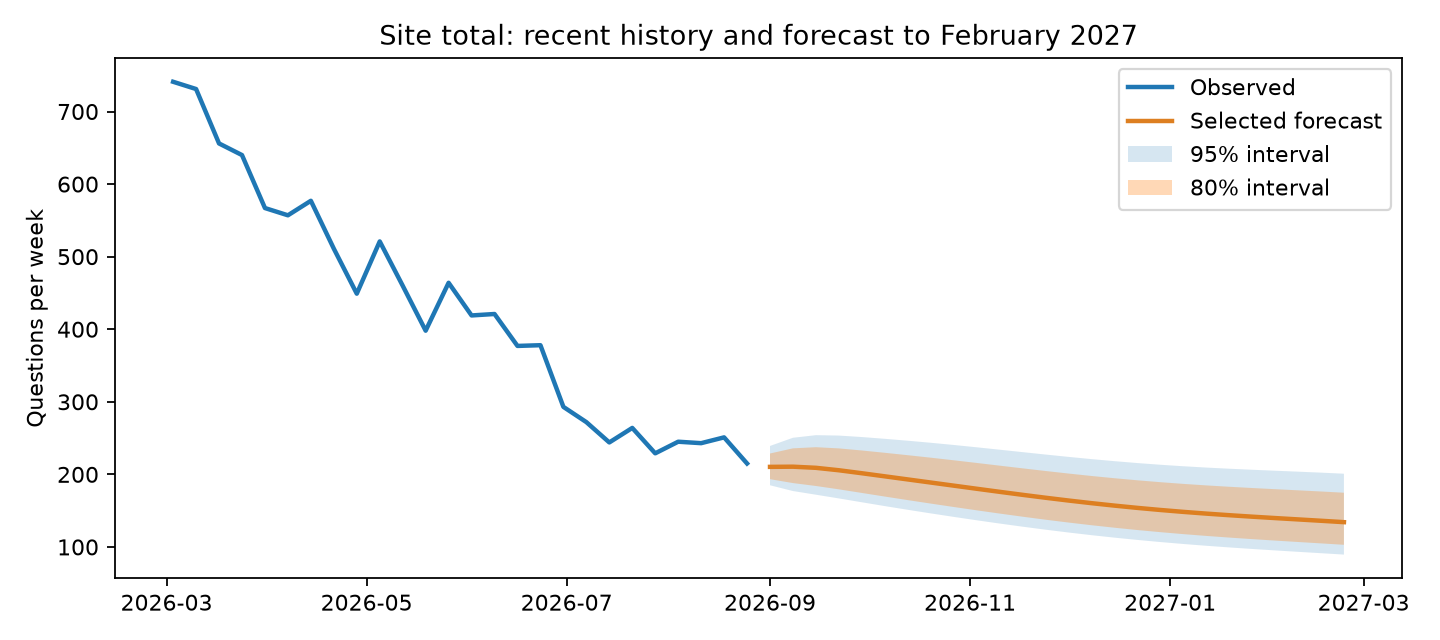

In [7]:
fc=pd.read_csv(TS/'forecasts_26w.csv');chosen=fc[fc.selected]
assert chosen.groupby('tag').size().eq(26).all()
assert chosen.week_start.max()=='2027-02-23'
display(pd.read_csv(TS/'tag_classes.csv'))
figure('reports/review2/ts/forecast_ALL.png')